# Step 3: Communities, Cores and Bridges

**This notebook currently covers Sections 3.0 to 3.2 only:** network projections, Louvain community detection with modularity, and the weighted sensitivity analysis. k-core analysis, bridging roles and their relation to degree come later.

**Why this step matters.** H2 asks whether observed resilience differs from degree-preserving randomized networks, and H3 asks whether bridging positions matter beyond degree. Both need a defensible description of how each airline's airports group together.

**Representations used here**

| Name | Graph | Weights | Role |
|---|---|---|---|
| `graphs` | Directed | `frequency` | Original network, never modified |
| `D_binary` | Directed | None | Primary topology for the null-model and resilience steps |
| `U_binary` | Undirected | None | **Primary** projection for communities |
| `U_weighted` | Undirected | `weight` = sum of flights in both directions | **Supplementary** sensitivity analysis |

## Section 3.0: Network projections

In [1]:
import hashlib
import os
import platform
from itertools import combinations
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

# Local execution is enabled only when this environment variable is set.
# It is not set on Colab, so Colab always uses the Google Drive path below.
LOCAL_PROJECT_ROOT = os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")

if LOCAL_PROJECT_ROOT:
    BASE = Path(LOCAL_PROJECT_ROOT) / "Data"
else:
    from google.colab import drive
    drive.mount("/content/drive")

    # Notice the trailing space after 'Network Analysis '
    BASE = Path("/content/drive/MyDrive/Network Analysis /Data")

RAW = BASE / "raw"
PROCESSED = BASE / "Processed"

PROJECT_ROOT = BASE.parent
RESULTS = PROJECT_ROOT / "Results"
FIGURES = RESULTS / "Figures"
TABLES = RESULTS / "Tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

AIRLINES = {
    "AA": "American Airlines",
    "DL": "Delta Air Lines",
    "WN": "Southwest Airlines"
}

# Community-detection settings used for every airline
LOUVAIN_RESOLUTION = 1.0
LOUVAIN_SEEDS = list(range(100))

print("Processed directory exists:", PROCESSED.exists())
print("Runs per airline:", len(LOUVAIN_SEEDS), "| resolution:", LOUVAIN_RESOLUTION)

Processed directory exists: True
Runs per airline: 100 | resolution: 1.0


**Load the original networks.** The node and edge files are read exactly as in Notebook 02. A fingerprint of each network is stored here and checked again at the end of the notebook, which proves the originals were not altered.

In [2]:
def network_fingerprint(G):
    """Hash of every node and every (source, target, frequency) edge."""
    payload = repr((
        sorted(G.nodes()),
        sorted((u, v, d["frequency"]) for u, v, d in G.edges(data=True))
    ))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


graphs = {}
airport_tables = {}

for airline in AIRLINES:
    nodes = pd.read_csv(PROCESSED / f"{airline}_nodes.csv")
    edges = pd.read_csv(PROCESSED / f"{airline}_edges.csv")

    G = nx.DiGraph(airline=airline)

    for row in nodes.itertuples(index=False):
        G.add_node(int(row.airport_id), code=row.code, city=row.city, state=row.state)

    for row in edges.itertuples(index=False):
        G.add_edge(int(row.source), int(row.target), frequency=float(row.frequency))

    assert G.number_of_nodes() == len(nodes)
    assert G.number_of_edges() == len(edges)

    graphs[airline] = G
    airport_tables[airline] = nodes

original_fingerprints = {a: network_fingerprint(G) for a, G in graphs.items()}

for airline, G in graphs.items():
    print(f"{airline}: {G.number_of_nodes()} airports, {G.number_of_edges()} directed routes")

AA: 230 airports, 1808 directed routes
DL: 212 airports, 1506 directed routes
WN: 104 airports, 1792 directed routes


**Build the projections.** Each projection is built from a sorted edge list, because Louvain's result for a given seed depends on node order. `nx.Graph(G)` is deliberately not used for weights: on a reciprocal network it keeps the frequency of only one direction. Here, both directions are summed explicitly.

In [3]:
def to_directed_binary(G):
    D = nx.DiGraph(airline=G.graph["airline"])
    D.add_nodes_from(sorted(G.nodes()))
    D.add_edges_from(sorted(G.edges()))
    return D


def to_undirected_binary(G):
    U = nx.Graph(airline=G.graph["airline"])
    U.add_nodes_from(sorted(G.nodes()))
    U.add_edges_from(sorted({(min(u, v), max(u, v)) for u, v in G.edges()}))
    return U


def to_undirected_weighted(G):
    totals = {}

    for u, v, data in G.edges(data=True):
        pair = (min(u, v), max(u, v))
        totals[pair] = totals.get(pair, 0.0) + data["frequency"]

    W = nx.Graph(airline=G.graph["airline"])
    W.add_nodes_from(sorted(G.nodes()))

    for (u, v), weight in sorted(totals.items()):
        W.add_edge(u, v, weight=weight)

    return W


D_binary = {a: to_directed_binary(G) for a, G in graphs.items()}
U_binary = {a: to_undirected_binary(G) for a, G in graphs.items()}
U_weighted = {a: to_undirected_weighted(G) for a, G in graphs.items()}

print("Projections built for:", ", ".join(U_binary))

Projections built for: AA, DL, WN


**Validate the projections** against the original networks and the Step 1 and Step 2 exports.

In [4]:
network_summary = pd.read_csv(PROCESSED / "network_summary.csv").set_index("Airline")
step2_summary = pd.read_csv(TABLES / "02_final_network_comparison.csv").set_index("Airline")

validation_rows = []

for airline, G in graphs.items():
    D, U, W = D_binary[airline], U_binary[airline], U_weighted[airline]
    n, m = G.number_of_nodes(), G.number_of_edges()
    total_flights = sum(d["frequency"] for _, _, d in G.edges(data=True))

    # Node sets and edge counts
    assert set(D) == set(U) == set(W) == set(G)
    assert D.number_of_edges() == m
    assert set(D.edges()) == set(G.edges())
    assert U.number_of_edges() == m / 2
    assert set(U.edges()) == set(W.edges())

    # Simple graphs, no leaked weights in binary projections
    for H in (D, U, W):
        assert nx.number_of_selfloops(H) == 0
    assert all(len(d) == 0 for _, _, d in D.edges(data=True))
    assert all(len(d) == 0 for _, _, d in U.edges(data=True))

    # Reciprocity and degree consistency
    assert nx.reciprocity(D) == 1.0
    assert all(D.in_degree(v) == D.out_degree(v) == U.degree(v) for v in G)
    assert nx.is_connected(U)

    # Each undirected weight equals the explicit two-direction sum
    assert all(
        d["weight"] == G[u][v]["frequency"] + G[v][u]["frequency"]
        for u, v, d in W.edges(data=True)
    )
    assert np.isclose(W.size(weight="weight"), total_flights)

    # Agreement with earlier validated exports
    assert n == step2_summary.loc[airline, "Airports"]
    assert m == step2_summary.loc[airline, "Directed routes"]
    assert np.isclose(total_flights, network_summary.loc[airline, "Total scheduled flights"])

    unequal_pairs = sum(
        G[u][v]["frequency"] != G[v][u]["frequency"] for u, v in U.edges()
    )

    validation_rows.append({
        "Airline": airline,
        "Airports": n,
        "Directed binary edges": D.number_of_edges(),
        "Undirected edges": U.number_of_edges(),
        "Reciprocity": nx.reciprocity(D),
        "Total scheduled flights": total_flights,
        "Sum of undirected weights": W.size(weight="weight"),
        "Pairs with unequal directional frequency": unequal_pairs,
        "Undirected graph connected": nx.is_connected(U)
    })

projection_validation = pd.DataFrame(validation_rows)
display(projection_validation)

projection_validation.to_csv(TABLES / "03_projection_validation.csv", index=False)
print("PASS: All projections agree with the original networks.")

,Airline,Airports,Directed binary edges,Undirected edges,Reciprocity,Total scheduled flights,Sum of undirected weights,Pairs with unequal directional frequency,Undirected graph connected
0,AA,230,1808,904,1.0,514206.0,514206.0,299,True
1,DL,212,1506,753,1.0,418790.0,418790.0,104,True
2,WN,104,1792,896,1.0,359789.0,359789.0,209,True


PASS: All projections agree with the original networks.


## Section 3.1: Louvain community detection and modularity (primary, binary)

Louvain is a randomized heuristic, so one run can give one of several good partitions. We therefore run it with 100 recorded seeds, calculate modularity for every run, and keep the highest-modularity partition as the primary result. Ties are resolved by the lowest seed.

Agreement between partitions is measured with the **Adjusted Rand Index (ARI)**: 1 means identical groupings, and values near 0 mean agreement no better than chance. ARI does not depend on community numbering.

In [5]:
def canonical_labels(communities, node_order):
    """Stable labels: community 0 is the largest, ties by smallest airport ID."""
    ordered = sorted((sorted(c) for c in communities), key=lambda c: (-len(c), c[0]))
    mapping = {node: label for label, community in enumerate(ordered) for node in community}
    return np.array([mapping[node] for node in node_order], dtype=int)


def run_louvain_ensemble(graph, airline, weight):
    node_order = sorted(graph.nodes())
    run_rows, labels = [], []

    for seed in LOUVAIN_SEEDS:
        communities = nx.community.louvain_communities(
            graph, weight=weight, resolution=LOUVAIN_RESOLUTION, seed=seed
        )
        modularity = nx.community.modularity(
            graph, communities, weight=weight, resolution=LOUVAIN_RESOLUTION
        )
        label_vector = canonical_labels(communities, node_order)
        sizes = np.bincount(label_vector)

        labels.append(label_vector)
        run_rows.append({
            "Airline": airline,
            "Seed": seed,
            "Modularity": modularity,
            "Communities": len(communities),
            "Largest community": int(sizes.max()),
            "Smallest community": int(sizes.min())
        })

    runs = pd.DataFrame(run_rows)
    labels = np.vstack(labels)
    q = runs["Modularity"].to_numpy()
    best_index = int(np.flatnonzero(q >= q.max() - 1e-12)[0])

    return runs, labels, best_index, node_order


def pairwise_ari(labels):
    return np.array([
        adjusted_rand_score(labels[i], labels[j])
        for i, j in combinations(range(len(labels)), 2)
    ])


def independent_modularity(graph, label_vector, node_order, weight):
    """Newman modularity written out directly, as a check on NetworkX."""
    label_of = dict(zip(node_order, label_vector))
    k = len(set(label_vector))
    internal, degree_sum = np.zeros(k), np.zeros(k)
    m = 0.0

    for u, v, data in graph.edges(data=True):
        w = data[weight] if weight else 1.0
        m += w
        degree_sum[label_of[u]] += w
        degree_sum[label_of[v]] += w
        if label_of[u] == label_of[v]:
            internal[label_of[u]] += w

    return float(np.sum(internal / m - (degree_sum / (2 * m)) ** 2))


def summarize_ensemble(airline, graph, runs, labels, best_index, node_order, weight):
    q = runs["Modularity"]
    best_labels = labels[best_index]
    sizes = np.sort(np.bincount(best_labels))[::-1]

    pair_ari = pairwise_ari(labels)
    to_best = np.array([adjusted_rand_score(best_labels, row) for row in labels])
    unique_partitions = len({tuple(row) for row in labels})
    runs_matching_best = int(sum(np.array_equal(row, best_labels) for row in labels))

    check = independent_modularity(graph, best_labels, node_order, weight)
    assert np.isclose(check, q.iloc[best_index]), "Modularity check failed"
    assert np.bincount(best_labels).sum() == graph.number_of_nodes()

    return {
        "Airline": airline,
        "Airports": graph.number_of_nodes(),
        "Best seed": int(runs["Seed"].iloc[best_index]),
        "Best modularity": float(q.iloc[best_index]),
        "Mean modularity": float(q.mean()),
        "SD modularity": float(q.std(ddof=1)),
        "Min modularity": float(q.min()),
        "Communities (best)": len(sizes),
        "Communities min across runs": int(runs["Communities"].min()),
        "Communities median across runs": float(runs["Communities"].median()),
        "Communities max across runs": int(runs["Communities"].max()),
        "Community sizes (best)": ", ".join(map(str, sizes)),
        "Largest community share (%)": float(100 * sizes[0] / sizes.sum()),
        "Distinct partitions in 100 runs": unique_partitions,
        "Runs identical to best": runs_matching_best,
        "Pairwise ARI mean": float(pair_ari.mean()),
        "Pairwise ARI median": float(np.median(pair_ari)),
        "Pairwise ARI min": float(pair_ari.min()),
        "Pairwise ARI 2.5%": float(np.percentile(pair_ari, 2.5)),
        "Pairwise ARI 97.5%": float(np.percentile(pair_ari, 97.5)),
        "ARI to best mean": float(to_best.mean()),
        "ARI to best min": float(to_best.min())
    }, pair_ari


# ARI sanity checks: identical up to relabeling gives 1
_example = np.array([0, 0, 1, 1, 2, 2])
assert np.isclose(adjusted_rand_score(_example, (_example + 1) % 3), 1.0)
print("ARI sanity check passed.")

ARI sanity check passed.


In [6]:
binary_runs, binary_labels, binary_best, binary_summary, binary_pair_ari = {}, {}, {}, [], {}
node_orders = {}

for airline in AIRLINES:
    runs, labels, best_index, node_order = run_louvain_ensemble(U_binary[airline], airline, None)
    summary, pair_ari = summarize_ensemble(
        airline, U_binary[airline], runs, labels, best_index, node_order, None
    )

    binary_runs[airline] = runs
    binary_labels[airline] = labels
    binary_best[airline] = labels[best_index]
    binary_summary.append(summary)
    binary_pair_ari[airline] = pair_ari
    node_orders[airline] = node_order

binary_summary_df = pd.DataFrame(binary_summary)

pd.concat(binary_runs.values(), ignore_index=True).to_csv(
    TABLES / "03_louvain_binary_runs.csv", index=False
)
binary_summary_df.to_csv(TABLES / "03_louvain_binary_summary.csv", index=False)

display(binary_summary_df.set_index("Airline").T)

Airline,AA,DL,WN
Airports,230,212,104
Best seed,72,27,96
Best modularity,0.21174,0.226523,0.190161
Mean modularity,0.199183,0.217065,0.184639
SD modularity,0.004146,0.00239,0.003376
Min modularity,0.185906,0.209194,0.173512
Communities (best),5,5,3
Communities min across runs,3,4,3
Communities median across runs,5.0,6.0,3.0
Communities max across runs,5,8,4


**Describe the primary communities.** The airports with the most routes are listed so each community can be read in airline terms. Degree here is a label only and no bridging quantity is calculated.

In [7]:
def airport_community_table(airline, labels_by_node, column):
    table = airport_tables[airline].rename(columns={
        "airport_id": "AirportID", "code": "Code", "city": "City", "state": "State"
    }).copy()
    table.insert(0, "Airline", airline)
    table[column] = table["AirportID"].map(labels_by_node)
    assert table[column].notna().all()
    table[column] = table[column].astype(int)
    return table


def community_profile(airline, table, column, graph):
    degree = dict(graph.degree())
    frame = table.assign(Degree=table["AirportID"].map(degree))
    rows = []

    for label, members in frame.groupby(column):
        top = members.sort_values(["Degree", "Code"], ascending=[False, True]).head(5)
        rows.append({
            "Airline": airline,
            "Community": int(label),
            "Airports": len(members),
            "Share of airports (%)": 100 * len(members) / len(frame),
            "Top airports by routes": ", ".join(f"{c} ({d})" for c, d in zip(top["Code"], top["Degree"]))
        })

    return rows


binary_tables, profile_rows = [], []

for airline in AIRLINES:
    labels_by_node = dict(zip(node_orders[airline], binary_best[airline]))
    table = airport_community_table(airline, labels_by_node, "Community")
    binary_tables.append(table)
    profile_rows.extend(community_profile(airline, table, "Community", U_binary[airline]))

airport_communities_binary = pd.concat(binary_tables, ignore_index=True)
binary_profile_df = pd.DataFrame(profile_rows)

airport_communities_binary.to_csv(TABLES / "03_airport_communities_binary.csv", index=False)
binary_profile_df.to_csv(TABLES / "03_community_profiles_binary.csv", index=False)

with pd.option_context("display.max_colwidth", None):
    display(binary_profile_df.round(1))

,Airline,Community,Airports,Share of airports (%),Top airports by routes
0,AA,0,86,37.4,"DFW (182), PHX (92), LAX (45), ATL (8), OKC (8)"
1,AA,1,51,22.2,"PHL (88), DCA (86), LGA (58), BOS (24), CMH (11)"
2,AA,2,49,21.3,"CLT (136), MIA (75), JAX (7), MKE (7), BDL (6)"
3,AA,3,29,12.6,"ORD (136), AUS (11), AGS (10), ASE (5), BZN (4)"
4,AA,4,15,6.5,"JFK (24), SDF (15), RDU (13), BNA (12), PIT (12)"
5,DL,0,79,37.3,"MSP (118), DTW (100), JFK (57), BOS (54), ORD (8)"
6,DL,1,57,26.9,"ATL (154), LGA (75), IAH (6), MSN (5), STL (5)"
7,DL,2,54,25.5,"SLC (89), SEA (47), LAX (44), LAS (15), MCI (10)"
8,DL,3,13,6.1,"RDU (21), CVG (18), DCA (17), MCO (16), BNA (13)"
9,DL,4,9,4.2,"AUS (23), IND (10), MSY (9), MEM (8), JAX (7)"


### Interpretation of the primary binary results

**Organization.** The selected partitions have modularity Q = 0.212 (AA, 5 communities), 0.227 (DL, 5 communities) and 0.190 (WN, 3 communities). Reading the largest airports in each community, the groups are mostly organized around one or more major hubs: for example, DFW with PHX and LAX for AA, and ATL with LGA for DL. WN divides into three large groups led by MDW/BNA/BWI, DEN/LAS/PHX and DAL/HOU/STL. These labels describe only the largest airports in each community.

**Strength of structure.** These modularity values are modest. They cannot yet be called higher or lower than expected, because that requires the degree-preserving null ensembles from Step 4. The differences between airlines are small and the networks differ in size, so they should not be ranked on Q alone.

**Stability.** Agreement across seeds is moderate: the mean pairwise ARI is 0.698 (AA), 0.724 (DL) and 0.634 (WN). Almost every run produced a different partition (100, 99 and 83 distinct partitions in 100 runs), and each selected partition was found by exactly one seed. The selected partition is therefore the best one *found in 100 seeds*, and it may not be the global optimum. Its mean ARI to the other runs is 0.613 (AA), 0.623 (DL) and 0.635 (WN), so for AA and DL it agrees with the other runs less than typical pairs of runs agree with each other.

**Implication.** The broad grouping around hubs recurs, but the assignment of individual airports, especially small ones, is uncertain. Any later measure based on a single partition should be checked for sensitivity to the partition used.

## Section 3.2: Weighted sensitivity analysis (supplementary)

This section repeats the same 100 seeds on `U_weighted`, where an edge's weight is the total number of scheduled flights in both directions. **The binary results remain the primary findings.**

Louvain varies from seed to seed, so a low ARI between two single partitions could reflect randomness rather than flight frequency. To separate those, we compare all 100 binary runs with all 100 weighted runs and set that agreement against the agreement seen within each ensemble.

In [8]:
weighted_runs, weighted_labels, weighted_best, weighted_summary, weighted_pair_ari = {}, {}, {}, [], {}

for airline in AIRLINES:
    runs, labels, best_index, node_order = run_louvain_ensemble(U_weighted[airline], airline, "weight")
    assert node_order == node_orders[airline]
    summary, pair_ari = summarize_ensemble(
        airline, U_weighted[airline], runs, labels, best_index, node_order, "weight"
    )

    weighted_runs[airline] = runs
    weighted_labels[airline] = labels
    weighted_best[airline] = labels[best_index]
    weighted_summary.append(summary)
    weighted_pair_ari[airline] = pair_ari

weighted_summary_df = pd.DataFrame(weighted_summary)

pd.concat(weighted_runs.values(), ignore_index=True).to_csv(
    TABLES / "03_louvain_weighted_runs.csv", index=False
)
weighted_summary_df.to_csv(TABLES / "03_louvain_weighted_summary.csv", index=False)

display(weighted_summary_df.set_index("Airline").T)

Airline,AA,DL,WN
Airports,230,212,104
Best seed,3,0,8
Best modularity,0.240811,0.266251,0.266941
Mean modularity,0.232718,0.264952,0.264867
SD modularity,0.003952,0.003039,0.001977
Min modularity,0.222272,0.252355,0.247243
Communities (best),4,5,4
Communities min across runs,3,4,3
Communities median across runs,4.0,5.0,4.0
Communities max across runs,5,5,4


In [9]:
def communities_from_labels(label_vector, node_order):
    groups = {}
    for node, label in zip(node_order, label_vector):
        groups.setdefault(int(label), set()).add(node)
    return list(groups.values())


def match_weighted_to_binary(binary, weighted):
    """Match community labels by largest overlap; return weighted labels in binary numbering."""
    overlap = pd.crosstab(pd.Series(binary, name="b"), pd.Series(weighted, name="w"))
    row, col = linear_sum_assignment(-overlap.to_numpy())
    mapping = {overlap.columns[c]: overlap.index[r] for r, c in zip(row, col)}
    next_label = int(max(binary)) + 1

    for label in overlap.columns:
        if label not in mapping:
            mapping[label] = next_label
            next_label += 1

    return np.array([mapping[w] for w in weighted])


comparison_rows, weighted_tables, weighted_profile_rows = [], [], []

for airline in AIRLINES:
    order = node_orders[airline]
    b_runs, w_runs = binary_labels[airline], weighted_labels[airline]
    b_best, w_best = binary_best[airline], weighted_best[airline]

    cross = np.array([
        adjusted_rand_score(b, w) for b in b_runs for w in w_runs
    ])
    same_seed = np.array([
        adjusted_rand_score(b, w) for b, w in zip(b_runs, w_runs)
    ])

    b_comm = communities_from_labels(b_best, order)
    w_comm = communities_from_labels(w_best, order)
    U, W = U_binary[airline], U_weighted[airline]

    matched = match_weighted_to_binary(b_best, w_best)
    moved = matched != b_best

    table = airport_community_table(airline, dict(zip(order, w_best)), "Community_weighted")
    table["Community_binary"] = table["AirportID"].map(dict(zip(order, b_best))).astype(int)
    table["Community_weighted_matched_to_binary"] = table["AirportID"].map(dict(zip(order, matched))).astype(int)
    table["Reassigned"] = table["AirportID"].map(dict(zip(order, moved))).astype(bool)
    weighted_tables.append(table)
    weighted_profile_rows.extend(
        community_profile(airline, table, "Community_weighted", W)
    )

    degree = dict(U.degree())
    hubs = sorted(order, key=lambda v: (-degree[v], U.number_of_nodes()))[:10]
    code_of = dict(zip(table["AirportID"], table["Code"]))
    moved_of = dict(zip(order, moved))

    comparison_rows.append({
        "Airline": airline,
        "ARI best binary vs best weighted": adjusted_rand_score(b_best, w_best),
        "Binary within-ensemble ARI mean": float(binary_pair_ari[airline].mean()),
        "Weighted within-ensemble ARI mean": float(weighted_pair_ari[airline].mean()),
        "Cross ARI mean (100 x 100)": float(cross.mean()),
        "Cross ARI 2.5%": float(np.percentile(cross, 2.5)),
        "Cross ARI 97.5%": float(np.percentile(cross, 97.5)),
        "Same-seed ARI mean": float(same_seed.mean()),
        "Communities binary": len(b_comm),
        "Communities weighted": len(w_comm),
        "Q binary partition on binary graph": nx.community.modularity(U, b_comm, weight=None),
        "Q weighted partition on binary graph": nx.community.modularity(U, w_comm, weight=None),
        "Q weighted partition on weighted graph": nx.community.modularity(W, w_comm, weight="weight"),
        "Q binary partition on weighted graph": nx.community.modularity(W, b_comm, weight="weight"),
        "Airports reassigned after matching": int(moved.sum()),
        "Airports reassigned (%)": 100 * float(moved.mean()),
        "Top-10 route hubs reassigned": ", ".join(code_of[v] for v in hubs if moved_of[v]) or "none"
    })

comparison_df = pd.DataFrame(comparison_rows)
airport_communities_weighted = pd.concat(weighted_tables, ignore_index=True)
weighted_profile_df = pd.DataFrame(weighted_profile_rows)

comparison_df.to_csv(TABLES / "03_binary_vs_weighted_comparison.csv", index=False)
airport_communities_weighted.to_csv(TABLES / "03_airport_communities_weighted.csv", index=False)
weighted_profile_df.to_csv(TABLES / "03_community_profiles_weighted.csv", index=False)

display(comparison_df.set_index("Airline").T)

with pd.option_context("display.max_colwidth", None):
    display(weighted_profile_df.round(1))

Airline,AA,DL,WN
ARI best binary vs best weighted,0.450666,0.456468,0.529181
Binary within-ensemble ARI mean,0.697617,0.724312,0.633949
Weighted within-ensemble ARI mean,0.880401,0.937882,0.886143
Cross ARI mean (100 x 100),0.372112,0.436437,0.433289
Cross ARI 2.5%,0.322365,0.371802,0.312715
Cross ARI 97.5%,0.435082,0.478032,0.576615
Same-seed ARI mean,0.371595,0.437986,0.435044
Communities binary,5,5,3
Communities weighted,4,5,4
Q binary partition on binary graph,0.21174,0.226523,0.190161


,Airline,Community,Airports,Share of airports (%),Top airports by routes
0,AA,0,104,45.2,"DFW (182), PHX (92), LAX (45), AUS (11), LAS (9)"
1,AA,1,50,21.7,"CLT (136), AGS (10), ILM (8), AVL (7), GSO (7)"
2,AA,2,42,18.3,"PHL (88), DCA (86), MIA (75), LGA (58), BOS (24)"
3,AA,3,34,14.8,"ORD (136), STL (10), DSM (8), DTW (8), GRR (8)"
4,DL,0,75,35.4,"ATL (154), MSY (9), MEM (8), SDF (8), JAX (7)"
5,DL,1,55,25.9,"SLC (89), SEA (47), LAX (44), LAS (15), DEN (9)"
6,DL,2,50,23.6,"MSP (118), DTW (100), MCI (10), EWR (7), GRB (7)"
7,DL,3,28,13.2,"LGA (75), JFK (57), BOS (54), RDU (21), CVG (18)"
8,DL,4,4,1.9,"AUS (23), HRL (2), MAF (1), MFE (1)"
9,WN,0,47,45.2,"MDW (75), BNA (73), BWI (67), STL (57), MCO (51)"


**Figures.** The first shows run-to-run variability of the primary analysis. The second compares community sizes between the two projections.

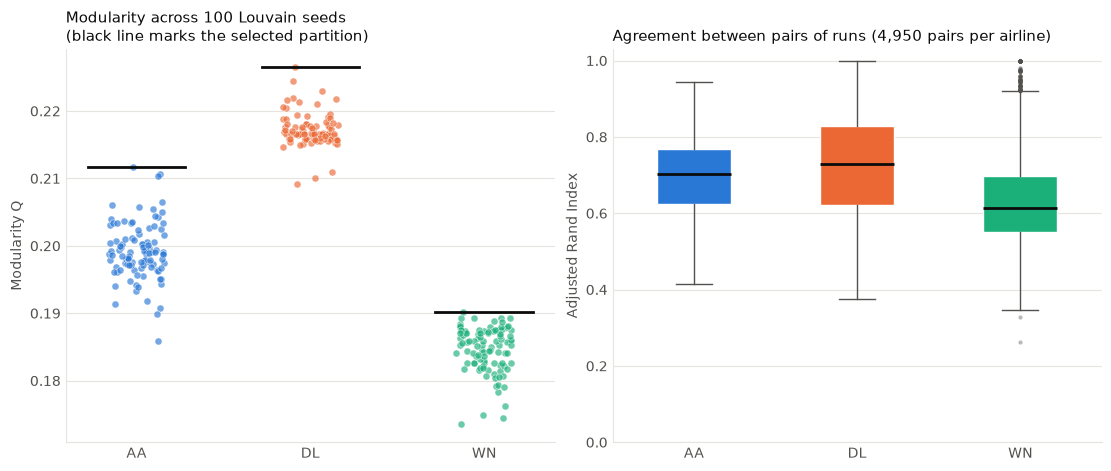

In [10]:
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
AIRLINE_COLORS = {"AA": "#2a78d6", "DL": "#eb6834", "WN": "#1baf7a"}
PROJECTION_COLORS = {"Binary (primary)": "#6250d6", "Weighted (supplementary)": "#eda100"}


def style_axis(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


rng = np.random.default_rng(0)  # only used to spread overlapping points horizontally
fig, (ax_q, ax_ari) = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)

for position, airline in enumerate(AIRLINES):
    q = binary_runs[airline]["Modularity"].to_numpy()
    jitter = rng.uniform(-0.16, 0.16, len(q))
    ax_q.scatter(position + jitter, q, s=26, color=AIRLINE_COLORS[airline], alpha=0.65,
                 edgecolor="white", linewidth=0.5, label=airline)
    ax_q.plot([position - 0.28, position + 0.28], [q.max()] * 2, color=INK, linewidth=2)

ax_q.set_xticks(range(len(AIRLINES)), list(AIRLINES))
ax_q.set_ylabel("Modularity Q", color=MUTED)
ax_q.set_title("Modularity across 100 Louvain seeds\n(black line marks the selected partition)",
               color=INK, fontsize=11, loc="left")
style_axis(ax_q)

parts = ax_ari.boxplot(
    [binary_pair_ari[a] for a in AIRLINES],
    tick_labels=list(AIRLINES), widths=0.45, patch_artist=True,
    medianprops={"color": INK, "linewidth": 2}, flierprops={"marker": "o", "markersize": 3,
    "markerfacecolor": MUTED, "markeredgecolor": "none", "alpha": 0.4},
    whiskerprops={"color": MUTED}, capprops={"color": MUTED}
)
for patch, airline in zip(parts["boxes"], AIRLINES):
    patch.set_facecolor(AIRLINE_COLORS[airline])
    patch.set_edgecolor("white")

ax_ari.set_ylim(0, 1.03)
ax_ari.set_ylabel("Adjusted Rand Index", color=MUTED)
ax_ari.set_title("Agreement between pairs of runs (4,950 pairs per airline)",
                 color=INK, fontsize=11, loc="left")
style_axis(ax_ari)

fig.savefig(FIGURES / "03_louvain_stability_binary.png", dpi=300, bbox_inches="tight")
plt.show()

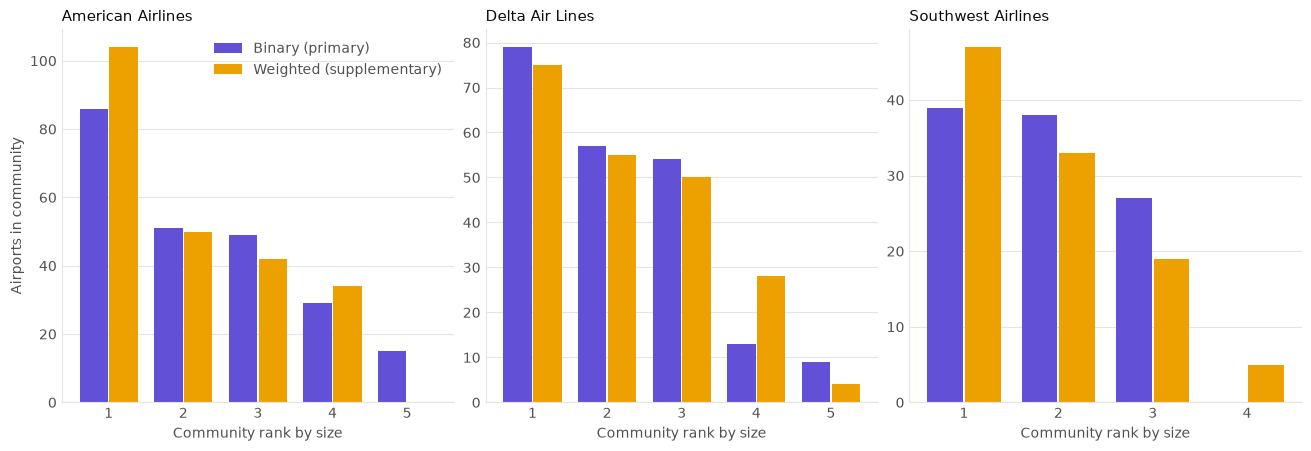

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)

for ax, airline in zip(axes, AIRLINES):
    binary_sizes = np.sort(np.bincount(binary_best[airline]))[::-1]
    weighted_sizes = np.sort(np.bincount(weighted_best[airline]))[::-1]
    max_len = max(len(binary_sizes), len(weighted_sizes))
    x = np.arange(1, max_len + 1)
    width = 0.38

    b = np.pad(binary_sizes, (0, max_len - len(binary_sizes)))
    w = np.pad(weighted_sizes, (0, max_len - len(weighted_sizes)))

    ax.bar(x - width / 2 - 0.01, b, width, color=PROJECTION_COLORS["Binary (primary)"], label="Binary (primary)")
    ax.bar(x + width / 2 + 0.01, w, width, color=PROJECTION_COLORS["Weighted (supplementary)"], label="Weighted (supplementary)")
    ax.set_xticks(x)
    ax.set_xlabel("Community rank by size", color=MUTED)
    ax.set_title(AIRLINES[airline], color=INK, fontsize=11, loc="left")
    style_axis(ax)

axes[0].set_ylabel("Airports in community", color=MUTED)
axes[0].legend(frameon=False, labelcolor=MUTED)

fig.savefig(FIGURES / "03_community_sizes_binary_vs_weighted.png", dpi=300, bbox_inches="tight")
plt.show()

**Final integrity checks** confirm the original networks are unchanged and record the software versions, because a given Louvain seed can produce a different partition under a different NetworkX version.

In [12]:
for airline, G in graphs.items():
    assert network_fingerprint(G) == original_fingerprints[airline], f"{airline} original network changed"

labels_binary = pd.read_csv(TABLES / "03_airport_communities_binary.csv")
centralities = pd.read_csv(TABLES / "02_airport_centralities.csv")
merged = centralities.merge(
    labels_binary[["Airline", "AirportID", "Community"]],
    on=["Airline", "AirportID"], how="outer", validate="one_to_one", indicator=True
)
assert (merged["_merge"] == "both").all()

run_metadata = pd.DataFrame([{
    "Python": platform.python_version(),
    "NetworkX": nx.__version__,
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "Louvain resolution": LOUVAIN_RESOLUTION,
    "Seeds": f"{LOUVAIN_SEEDS[0]}-{LOUVAIN_SEEDS[-1]}"
}])
run_metadata.to_csv(TABLES / "03_run_metadata.csv", index=False)
display(run_metadata)

print("PASS: Original directed weighted networks are unchanged.")
print("PASS: Every airport in the Step 2 table has exactly one community label.")

,Python,NetworkX,NumPy,pandas,SciPy,scikit-learn,Louvain resolution,Seeds
0,3.14.5,3.6.1,2.4.6,3.0.5,1.18.1,1.9.0,1.0,0-99


PASS: Original directed weighted networks are unchanged.
PASS: Every airport in the Step 2 table has exactly one community label.


### Interpretation of the weighted sensitivity analysis (supplementary)

**Does flight frequency change the community organization? Yes.** The selected binary and weighted partitions agree only moderately (ARI = 0.451 for AA, 0.456 for DL and 0.529 for WN). Across all 100 x 100 pairs of runs, mean agreement is 0.372, 0.436 and 0.433. That is clearly lower than agreement within either ensemble (binary 0.698, 0.724, 0.634; weighted 0.880, 0.938, 0.886), so the difference is not explained by seed-to-seed noise alone. The 95% ranges of binary-within and cross-projection ARI do not overlap for AA or DL, but they do overlap for WN.

**What changes.** After matching communities by overlap, 75 AA airports (32.6%), 59 DL airports (27.8%) and 24 WN airports (23.1%) change community. Among each airline's ten highest-degree hubs, MIA moves for AA, LGA, JFK and BOS move for DL, and STL moves for WN. Weighting gives Delta a distinct LGA/JFK/BOS-led community and gives Southwest a separate five-airport Hawaii community (HNL, OGG, KOA, LIH, ITO). The major groupings around DFW, ATL, SLC/SEA/LAX, DEN/LAS/PHX and MDW/BNA/BWI persist in both projections.

**Stability and modularity.** Weighted runs are considerably more stable than binary runs, because flight frequencies reduce the number of near-equivalent partitions. Weighted Q is higher in these runs (0.241, 0.266, 0.267), but Q values on different graphs are not directly comparable, so this does not show that the weighted partition is better.

**Decision.** The binary partition remains the primary result, as agreed: it describes the same route topology used by the null-model and resilience analyses. The weighted result shows that community membership depends meaningfully on whether route frequency is considered, and this should be stated as a limitation of community-based interpretation.

**Checkpoint.** Sections 3.0 to 3.2 are complete. k-core analysis, bridging roles and their relation to degree have not been started.